# 02 - The Primitives

Every Jev question is built from the same four parts:

| Part | What it is |
| --- | --- |
| **ID** | The key you choose. Identifies the answer. Never sent to the model. |
| `type` | `choice`, `score`, `noul`, or `box` |
| `instructions` | The question itself. This is where your evaluation logic lives. |
| `criteria` | The possible answers. Shape depends on the type. |

How to pick a type: prefer the one whose answer your code can act on directly.

- A **Choice** between `refund`, `rebook`, `information` maps onto three code paths.
- A **Score** of frustration maps onto a threshold.
- A **Noul** maps onto an `if`.
- A **Box** maps onto a crop of an image (preview feature, end of this notebook).

In [1]:
import os
from pathlib import Path

from dotenv import load_dotenv

# Find the TypeSafe API key: environment first, then any .env file up the tree.
if "TYPESAFE_API_KEY" not in os.environ:
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / ".env").exists():
            load_dotenv(folder / ".env")
            break
assert os.environ.get("TYPESAFE_API_KEY"), "Set TYPESAFE_API_KEY (get a key at console.typesafe.ai/keys)"

import typesafe_sdk

print("typesafe-sdk", typesafe_sdk.__version__, "ready")

typesafe-sdk 0.7.5 ready


In [2]:
PRICE_PER_MTOK = 0.042  # dollars per million input tokens; output tokens are free


def cost_usd(response):
    """What this call cost, in dollars."""
    return response.usage.input_tokens / 1_000_000 * PRICE_PER_MTOK


def show(response):
    """Pretty-print every answer in a response, plus tokens and cost."""
    print(f"model={response.model}  input_tokens={response.usage.input_tokens}  cost=${cost_usd(response):.6f}")
    for qid, a in response.answers.items():
        if a.type == "noul":
            print(f"  {qid:<28} noul={a.noul:.2f}")
        elif a.type == "choice":
            print(f"  {qid:<28} choice={a.choice!r}  confidence={a.confidence:.2f}")
            print(f"  {'':<28} probabilities={a.probabilities}")
        elif a.type == "score":
            print(f"  {qid:<28} score={a.score:.2f}  confidence={a.confidence:.2f}")
            print(f"  {'':<28} probabilities={a.probabilities}")
        else:
            print(f"  {qid:<28} {a}")

## Choice: pick one option from a fixed set

`criteria` is a map of option name to description (use `None` when the name speaks for
itself). Up to **255 options** per question. Both names and descriptions are sent to the
model, so write descriptions that separate neighboring options from each other.

Good practice: add an `other` / `none_of_the_above` option whenever your list might not
cover every input, so the model has somewhere honest to put its probability.

In [3]:
from typesafe_sdk import Choice, TypeSafeClient

with TypeSafeClient() as client:
    r = client.system_one(
        state="My running shoes arrived in the wrong size. Can I swap them for a size 10?",
        questions={
            "department": Choice(
                instructions="Which team should handle this?",
                criteria={
                    "returns": "Exchanges, wrong or damaged items",
                    "shipping": "Delivery status, delays, lost packages",
                    "billing": "Charges, invoices, payment problems",
                },
            ),
        },
    )
show(r)

model=jev-1.13.0  input_tokens=357  cost=$0.000015
  department                   choice='returns'  confidence=1.00
                               probabilities={'returns': 1.0, 'shipping': 0.0, 'billing': 0.0}


An easy ticket: all the probability lands on one option and confidence is 1.0.

Now an **ambiguous** ticket that genuinely belongs to two teams. Watch the probability
split, and watch `confidence` drop. This is the model being honest, not failing.
Your code can read the runner-up probability and CC the second team.

In [4]:
ambiguous = (
    "The shoes came in the wrong size AND I was charged twice for the order. "
    "I need this fixed."
)

with TypeSafeClient() as client:
    r = client.system_one(
        state=ambiguous,
        questions={
            "department": Choice(
                instructions="Which team should handle this?",
                criteria={
                    "returns": "Exchanges, wrong or damaged items",
                    "shipping": "Delivery status, delays, lost packages",
                    "billing": "Charges, invoices, payment problems",
                },
            ),
        },
    )
show(r)

dept = r.choices["department"]
for team, p in dept.probabilities.items():
    if team != dept.choice and p > 0.25:
        print(f"-> also notify {team} (probability {p:.2f})")

model=jev-1.13.0  input_tokens=358  cost=$0.000015
  department                   choice='returns'  confidence=0.37
                               probabilities={'returns': 0.58, 'shipping': 0.0, 'billing': 0.42}
-> also notify billing (probability 0.42)


### Structured criteria: when two options keep getting confused

A description can be an **object** instead of a string. The field names (`what`, `not_for`,
`examples`) are not part of the API; you choose them, and the model reads them as labels.
Use the same fields on every option so the model can compare like with like.

Here `return_policy` (a question about the rules) and `return_status` (a question about one
return in flight) both mention returns and refunds, so each option says what it is *not* for.

In [5]:
with TypeSafeClient() as client:
    r = client.system_one(
        state="Hi, I sent back order B-2041 last Tuesday. When does the money arrive?",
        questions={
            "return_topic": Choice(
                instructions="What is this ticket about?",
                criteria={
                    "return_policy": {
                        "what": "Questions about the return rules in general",
                        "not_for": "A specific return already in progress",
                        "examples": ["How long do I have to return?", "Do you cover postage?"],
                    },
                    "return_status": {
                        "what": "The progress of one specific return or refund",
                        "not_for": "General questions about the rules",
                        "examples": ["Where is my refund for order 123?"],
                    },
                },
            ),
        },
    )
show(r)

model=jev-1.13.0  input_tokens=426  cost=$0.000018
  return_topic                 choice='return_status'  confidence=1.00
                               probabilities={'return_policy': 0.0, 'return_status': 1.0}


## Score: rate against ordered, descriptive levels

`criteria` is an **ordered array** of level descriptions, low end first: at least 2 levels,
at most 10. A level's number is its position in the array, starting at 0.

The answer:

- `probabilities`: probability per level (the Python SDK keys these by **int**)
- `score`: the probability-weighted mean of level numbers. It can land **between** levels:
  probabilities `{0: 0.0, 1: 0.57, 2: 0.43}` give `score = 1*0.57 + 2*0.43 = 1.43`
- `legend`: your level descriptions mapped back by number
- `confidence`: how peaked the distribution is

The single most important rule for writing levels: **describe situations, not degrees.**
"Broken feature, but a workaround exists" gives the model something to match the state
against. "Moderately severe" does not. Each level is judged on its own; the model never
sees a level's number or its neighbours, so "worse than the previous level" means nothing.

In [6]:
import pandas as pd
from typesafe_sdk import Score, TypeSafeClient

SEVERITY = Score(
    instructions="How severe is the reported issue?",
    criteria=[
        "Cosmetic; no impact to functionality",
        "Broken or degraded feature, but workaround exists",
        "Blocking issue; no workaround exists",
    ],
)

reports = [
    "The export button is misaligned by a few pixels on the settings page.",
    "The PDF export button does nothing. I can still export CSV and convert it, but it takes ages.",
    "Export to PDF fails with a spinner that never finishes. For some of our team CSV fails too.",
    "The export button crashes the settings page in Safari. Works in Chrome, but some customers only use Safari.",
    "Nobody on our team can log in since this morning. 500 error on every attempt.",
]

rows = []
with TypeSafeClient() as client:
    for report in reports:
        r = client.system_one(state=report, questions={"severity": SEVERITY})
        a = r.scores["severity"]
        rows.append({
            "report": report[:58] + ("..." if len(report) > 58 else ""),
            "score": round(a.score, 2),
            "confidence": round(a.confidence, 2),
            **{f"P(level {k})": round(v, 2) for k, v in sorted(a.probabilities.items())},
        })

pd.DataFrame(rows)

,report,score,confidence,P(level 0),P(level 1),P(level 2)
0,The export button is misaligned by a few pixel...,0.00,1.00,1.0,0.00,0.00
1,The PDF export button does nothing. I can stil...,1.03,0.95,0.0,0.97,0.03
2,Export to PDF fails with a spinner that never ...,1.31,0.53,0.0,0.69,0.31
3,The export button crashes the settings page in...,1.42,0.37,0.0,0.58,0.42
4,Nobody on our team can log in since this morni...,2.00,1.00,0.0,0.00,1.00


Read the table like a story: clear reports pin all probability on one level (confidence 1.0),
while the Safari report splits between "workaround exists" and "no workaround", because *both
are true depending on the customer*. The fractional score ranks it between the two.

Caution: different distributions can produce the same score. A score of 1.0 can be
"all probability on level 1" or "half on 0, half on 2". Always read `probabilities` and
`confidence` alongside `score`.

### Anti-example: levels that are just numbers

What happens if we ignore the rule and give bare numbers as levels?
The model has nothing to match the state against.

In [7]:
cosmetic = reports[0]  # the misaligned button, clearly level 0

with TypeSafeClient() as client:
    bad = client.system_one(
        state=cosmetic,
        questions={
            "severity": Score(
                instructions="Rate severity from 0 to 2, where 2 is worst",
                criteria=["0", "1", "2"],
            ),
        },
    )
    good = client.system_one(state=cosmetic, questions={"severity": SEVERITY})

print("numbers-only levels:")
show(bad)
print()
print("descriptive levels:")
show(good)

numbers-only levels:
model=jev-1.13.0  input_tokens=320  cost=$0.000013
  severity                     score=0.58  confidence=0.37
                               probabilities={0: 0.42, 1: 0.58, 2: 0.0}

descriptive levels:
model=jev-1.13.0  input_tokens=332  cost=$0.000014
  severity                     score=0.00  confidence=1.00
                               probabilities={0: 1.0, 1: 0.0, 2: 0.0}


Two more Score rules worth memorizing:

- **One dimension per question.** "Punctual and smart and experienced" is three questions
  wearing one trench coat. An input high on one and low on another cannot be placed, so
  confidence drops and the score means less. Split it, combine in code (notebook 04).
- **Give rare extremes their own level.** If a sentiment scale ends at "very angry", an
  abusive message and an angry one both land near the top. Add "abusive or threatening"
  as its own level if your code must treat it differently.

## Noul: the probability that a statement is true

A Noul answer is **one number**: the probability that the answer is yes. Near 1 is a strong
yes, near 0 a strong no, near 0.5 means the model gives both similar probability. There is
no separate `confidence`: with only two outcomes, the value already says everything
(notebook 03 shows the `|2p - 1|` trick if you want one anyway).

Writing rules:

- One yes/no per question. "Angry AND asking for a refund" is two Nouls.
- Phrase so that high means yes. "Is the message free of personal data?" inverts the
  meaning and your thresholds will read backwards.
- Make the yes/no boundary unambiguous; "any" is a useful word. When the boundary is
  subtle, add `criteria` with explicit `true` and `false` descriptions.

In [8]:
import pandas as pd
from typesafe_sdk import Noul, NoulCriteria, TypeSafeClient

QUESTIONS = {
    "wants_human": Noul(instructions="Is the customer asking for a human agent?"),
    "repeat_contact": Noul(
        instructions="Has the customer contacted support about this before?",
        criteria=NoulCriteria(
            true="Mentions a prior attempt, ticket, or that they have asked before",
            false="No sign of any previous contact",
        ),
    ),
}

messages = [
    "Thanks, that fixed it!",
    "How do I reset my password?",
    "I need this sorted today, whatever it takes.",
    "Are you a bot?",
    "Is there any way to speak to someone about my invoice?",
    "I have asked three times now. Can I please just talk to a real person?",
]

rows = []
with TypeSafeClient() as client:
    for m in messages:
        r = client.system_one(state=m, questions=QUESTIONS)
        rows.append({
            "message": m,
            "wants_human": round(r.nouls["wants_human"].noul, 2),
            "repeat_contact": round(r.nouls["repeat_contact"].noul, 2),
        })

pd.DataFrame(rows)

,message,wants_human,repeat_contact
0,"Thanks, that fixed it!",0.03,0.25
1,How do I reset my password?,0.08,0.07
2,"I need this sorted today, whatever it takes.",0.27,0.12
3,Are you a bot?,0.40,0.06
4,Is there any way to speak to someone about my ...,0.84,0.10
5,I have asked three times now. Can I please jus...,0.99,0.94


The middle rows are the interesting ones. "I need this sorted today" is urgent but never asks
for a person. "Are you a bot?" hints without asking, and the model splits near 0.5. Those are
exactly the messages your code should threshold, or send to a reviewer:

```python
YES, NO = 0.8, 0.2
if NO < value < YES:
    send_to_review(message)   # the model told you it is unsure; believe it
```

### Noul is not a dial: probability of yes vs position on a scale

A trap worth demonstrating. A Noul value runs 0 to 1, but it is **not a measure of degree**.
Ask "Is the candidate strong in Python?" and the number is the probability of "strong",
whatever the model takes that to mean. If you want to *measure* experience, that is a Score
with levels you define. Same state, both questions:

In [9]:
import pandas as pd
from typesafe_sdk import Noul, Score, TypeSafeClient

candidates = [
    "My experience is in Java and Go. I have not used Python.",
    "I have used Python occasionally for small scripts alongside my main Java work.",
    "I used Python every day for two years in my last job, mostly data pipelines.",
    "I have written Python daily for eight years, including maintaining a large Django codebase.",
]

BOTH = {
    "strong_python": Noul(instructions="Is the candidate strong in Python?"),
    "python_experience": Score(
        instructions="How much Python experience does the candidate have?",
        criteria=[
            "No experience",
            "Some familiarity",
            "Regular use in a job",
            "Deep expertise",
        ],
    ),
}

rows = []
with TypeSafeClient() as client:
    for c in candidates:
        r = client.system_one(state=c, questions=BOTH)
        rows.append({
            "candidate": c[:64] + ("..." if len(c) > 64 else ""),
            "noul: strong?": round(r.nouls["strong_python"].noul, 2),
            "score: experience": round(r.scores["python_experience"].score, 2),
        })

pd.DataFrame(rows)

,candidate,noul: strong?,score: experience
0,My experience is in Java and Go. I have not us...,0.03,0.00
1,I have used Python occasionally for small scri...,0.14,1.00
2,I used Python every day for two years in my la...,0.81,2.05
3,"I have written Python daily for eight years, i...",0.92,2.87


The Noul column answers one proposition with an unspecified boundary. The Score column lands
each candidate on or near a level **you wrote**, and if you disagree with a placement you can
reword a level and rerun. Choose the type by the shape of the answer your code needs.

## Box and images (preview)

The fourth primitive finds **where something is in an image**. The answer is the smallest
rectangle around the target, as four edges (`top`, `bottom`, `left`, `right`), each a
**fraction** of the image's size measured from the top-left corner, so the same answer works
at any resolution.

Status and rules (as of Jev 1.14):

- Images and Box are "dreamer-ready": fine for prototypes, formats may change. Every request
  that includes an image or a Box question must send the header
  `TypeSafe-Danger-Zone-Images: true`.
- Box questions need **Jev 1.14**: send `model="jev-preview"` (or `jev-1.14.0`).
- Box takes no `criteria`, and the instructions need not be a question:
  "the coffee mug in `photo`" is enough.
- **There is no "not found".** A Box about something absent still returns four edges. Pair
  every Box with a Noul ("Is there a mug in `photo`?") and ignore the box when the Noul is low.
- Limits: PNG/JPEG only, 16 MiB per file, each side 280 to 1568 px.
- A practical gotcha we hit while building this workshop: image requests take seconds, not
  milliseconds. The SDK's default timeout is 10 s per HTTP operation, which image calls can
  exceed (and then the SDK retries, and the retries time out too). Raise `timeout` on the
  client for image work.

We will draw a synthetic scene so this cell has no external dependencies, then ask Jev where
the red circle is.

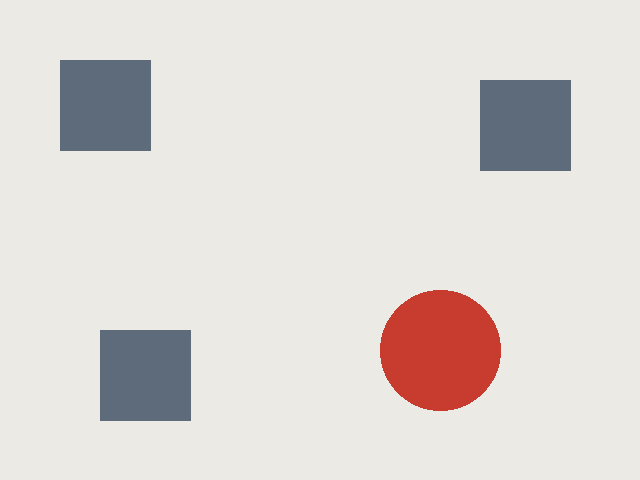

In [10]:
from PIL import Image as PILImage, ImageDraw

W, H = 640, 480
scene = PILImage.new("RGB", (W, H), "#ECEAE4")
draw = ImageDraw.Draw(scene)
for x, y in [(60, 60), (480, 80), (100, 330)]:
    draw.rectangle([(x, y), (x + 90, y + 90)], fill="#5E6B7A")
draw.ellipse([(380, 290), (500, 410)], fill="#C83C2F")  # the red circle
scene.save("../assets/scene.png")
scene

In [11]:
from pathlib import Path

from typesafe_sdk import Box, Image, Noul, TypeSafeClient

with TypeSafeClient(timeout=90) as client:  # images are slow; raise the timeout
    r = client.system_one(
        model="jev-preview",  # Box needs Jev 1.14
        state={"scene": Image(Path("../assets/scene.png"))},
        questions={
            "circle_present": Noul(instructions="Is there a red circle in `scene`?"),
            "circle": Box(instructions="the red circle in `scene`"),
        },
        extra_headers={"TypeSafe-Danger-Zone-Images": "true"},
    )

print(f"model={r.model}  input_tokens={r.usage.input_tokens} (images are billed as input tokens)")
print(f"circle present: {r.nouls['circle_present'].noul:.2f}")
box = r.boxes["circle"]
print(f"box: {box.box}  confidence={box.confidence:.2f}")

model=jev-1.14.0  input_tokens=1161 (images are billed as input tokens)
circle present: 0.99
box: top=0.6 bottom=0.87 left=0.1 right=0.79  confidence=0.21


ground truth: left 0.59, top 0.60, right 0.78, bottom 0.85


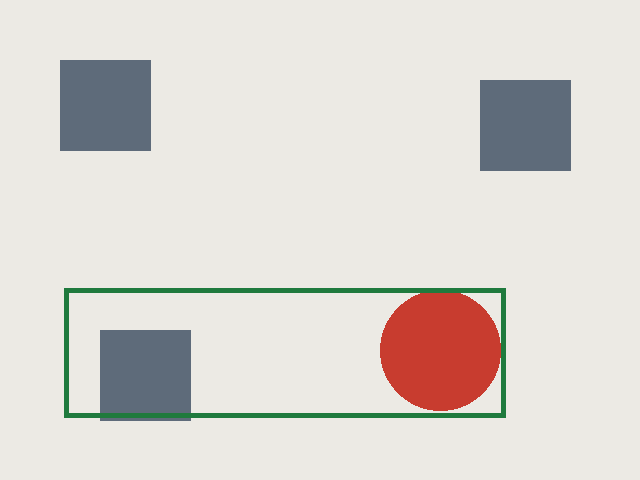

In [12]:
from PIL import ImageDraw

edges = box.box
annotated = scene.copy()
d = ImageDraw.Draw(annotated)
d.rectangle(
    [(edges.left * W, edges.top * H), (edges.right * W, edges.bottom * H)],
    outline="#1F7A3D",
    width=5,
)
print("ground truth: left 0.59, top 0.60, right 0.78, bottom 0.85")
annotated

Compare the drawn box with the circle, and look at the confidence. When we ran this, the
vertical edges were close to the truth, the horizontal ones were loose, and confidence was
low: the model told us it was not sure. That is the preview label being honest with you.
The docs suggest remedies: re-ask on a crop, pad the box before cropping, or verify each
edge with a Noul ("Does the circle in `crop` continue past the left edge?").

## Exercises

1. Add an `other` option to the department Choice, then send a ticket about a lost password.
   Where does the probability go?
2. Rewrite the severity Score with 5 levels including "data loss or security impact" at the
   top. Re-run the five reports.
3. Give `repeat_contact` structured criteria with `examples` on each side, and test a message
   like "my colleague emailed you last week about this".
4. Box: generate a scene with TWO red circles and ask for "the red circle nearest the top".
   Check the box and the confidence.